# Adaptive Optics Simulation — Part I using **AOtools**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GillesOrban/ao_school/blob/main/aotools_lab.ipynb)

## Run this cell first 
Run the cell below if you run the notebook on on Google Colab.
Skip if you run the notebook locally

In [ ]:
!git clone https://github.com/GillesOrban/ao_school.git
%cd ao_school
!pip install -r requirements.txt   # only non-preinstalled deps

import aotools
print("aotools OK")

Cloning into 'ao_school'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (38/38), done.
^Cceiving objects:  54% (27/50), 12.13 MiB | 89.00 KiB/s  
[Errno 2] No such file or directory: 'ao_school'
/Users/orban/github/ao_school
ERROR: Could not find a version that satisfies the requirement aotools (from versions: none)
ERROR: No matching distribution found for aotools


## What is AOtools ?
- collection of tools, equations and functions for Adaptive Optics, in Python.
- Full documentation can be found at [read-the-docs](https://aotools.readthedocs.io/en/latest/).
- Full AOtools package can be found [here](https://github.com/aotools/aotools/)
- A set of notebooks illustrating the functionalities of **AOtools** can be found [here](https://github.com/aotools/aotools_tests/)

## Objectives & plan
- **1. Image formation** basics: propagate from pupil to focal plane and measuring a PSF (first zero, encircled energy, FWHM)
- **2. Optical aberrations**: Zernike modes, wavefront error, Strehl ratio
- **3. Atmospheric turbulence**: $r_0$, seeing and $C_n^2$, with the $\lambda^{6/5}$ scaling, and estimate $\tau_0$ / $\theta_0$.
- **4. Generate phase screens**: Kolmogorov vs von Kármán (outer scale $L_0$), validation (Zernike power spectrum vs Noll 1976, structure function), infinite phase screens
- **5. Imaging through turbulence**: instantaneous & long-exposure PSFs, etc.

Today we will use:

| Functionality | `aotools` entry points |
|---|---|
| Fourier optics | `ft2`, `ift2` |
| Pupils & images | `circle`, `azimuthal_average`, `encircled_energy` |
| Aberrations | `zernikeArray`, `zernike_noll`, `zernike_nm`, `phaseFromZernikes`, `zernIndex` |
| Turbulence parameters | `r0_to_seeing`, `seeing_to_r0`, `r0_to_cn2`, `cn2_to_r0`, `coherenceTime`, `isoplanaticAngle` |
| Phase screens | `turbulence.phasescreen.ft_phase_screen`, `ft_sh_phase_screen`, `structure_function_kolmogorov`, `structure_function_vk` |

### Reminders and Conventions

- Phase screens from `aotools` are in **radians of phase**: $\mathrm{OPD\,[m]} = \phi\,[\mathrm{rad}] \times \lambda / 2\pi$.
- $r_0$ is quoted at $\lambda = 500$ nm unless stated otherwise, and scales as $r_0 \propto \lambda^{6/5}$.
- radian to arcseconds = 206264.8 -- arcseconds to radian: 4.848e-6

In [11]:
# ============================================================
# Setup — run this cell first
# ============================================================
# if %matplotlib widget doesn't work, try %matplotlib inline instead
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm

import aotools
from aotools.turbulence import (phasescreen, infinitephasescreen,
                                temporal_ps, slopecovariance, profile_compression)

import scipy.signal

from astropy.visualization import imshow_norm, LogStretch, LinearStretch, SqrtStretch, AsinhStretch, PercentileInterval


# Wavelength used throughout the notebook (r0 values are quoted at this wavelength)
WAVELENGTH = 500e-9  # [m]

# 1. Image formation (~20 min)
**Fourier optics, diffraction & image formation (~20min)**

Light propagation between conjugate planes is a **Fourier transform**. 
For a pupil sampled on $N$ pixels of size $\delta_x$ [m], `aotools.ft2` returns the focal-plane *field* with the correct physical scaling; the focal-plane pixel size is $1/(N\,\delta_x)$ [1/m]. 
The focal-plane pixel size in arcseconds is thus $\lambda/(N\,\delta_x) \times 206264.8 $ [arcsec/px] 

To avoid aliasing artifact, we need to increase the resolution and pad the pupil plane array with zeros.

See also [this book](https://www.spiedigitallibrary.org/ebooks/PM/Numerical-Simulation-of-Optical-Wave-Propagation-with-Examples-in-MATLAB/eISBN-9780819483270/10.1117/3.866274).

We will:
1. check the scaled FFT round-trip and the pixel scales;
2. compute the diffraction-limited PSF of a circular aperture (the **Airy pattern**);
3. measure it: first zero, encircled energy, FWHM, and the MTF cut-off at $D/\lambda$.

### 1.1 First look to aotools fourier transform

ft2/ift2 round-trip max error: 4.440892098500626e-16
Pupil pixel scale        : 0.0156 m/pxl
Fourier pixel scale      : 1.00 1/m
focal-plane angular pixel scale: 0.103 arcsec/pxl  (= lambda/(N*delta_x))


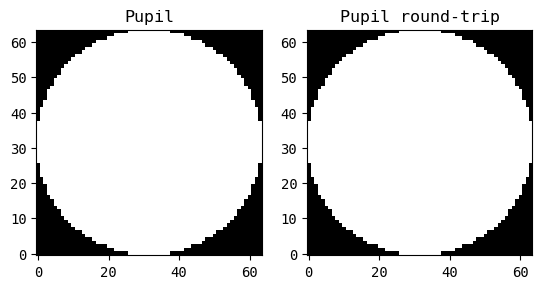

In [12]:
# --- 1.1 Scaled Fourier transforms --------------------------------------
N = 64           # pixels
D=1.0          # m (aperture diameter)
delta_x = D/64   # m per pixel (a 1 m aperture sampled on 64 pixels)

pupil = aotools.circle(N/2, N)          # centred disk, radius N/2 px

# Forward transform (pupil -> focal-plane field) and back
E_focal    = aotools.ft2(pupil, delta=delta_x)
pupil_back = aotools.ift2(E_focal, delta_f=1/(N*delta_x)).real

print('ft2/ift2 round-trip max error:', np.abs(pupil_back - pupil).max())

delta_f = 1/(N*delta_x)
print(f'Pupil pixel scale        : {delta_x:.4f} m/pxl')
print(f'Fourier pixel scale      : {delta_f:.2f} 1/m')
print(f'focal-plane angular pixel scale: {WAVELENGTH*delta_f*206265:.3f} arcsec/pxl  (= lambda/(N*delta_x))')


plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(pupil, cmap='gray')
plt.title('Pupil')
plt.subplot(1, 2, 2)
plt.imshow(pupil_back, cmap='gray')
plt.title('Pupil round-trip')
plt.show()

### 1.2 From pupil to PSF: the Airy pattern

The focal-plane **intensity** PSF is $|\mathcal{F}\{P\}|^2$. We assume here a perfectly flat wavefront ($\phi = 0$), such that the entrance electric field $E = P \exp{j \phi} = P$, with $P$ the pupil mask.

For a circular pupil of diameter $D$ this is the Airy pattern: a central peak of full width $\approx 1.03\,\lambda/D$ (FWHM), a first zero at $1.22\,\lambda/D$, and $\approx 84\%$ of the light within the first dark ring.

Zero-padding the pupil by a factor `pad_factor` samples the PSF `pad_factor`× finer — a minimum of a factor 2 is necessary to avoid aliasing/artifact (Nyquist-Shannon sampling theorem).

focal-plane pixel scale: 6.45 mas/pxl
diffraction limit lambda/D = 103.1 mas


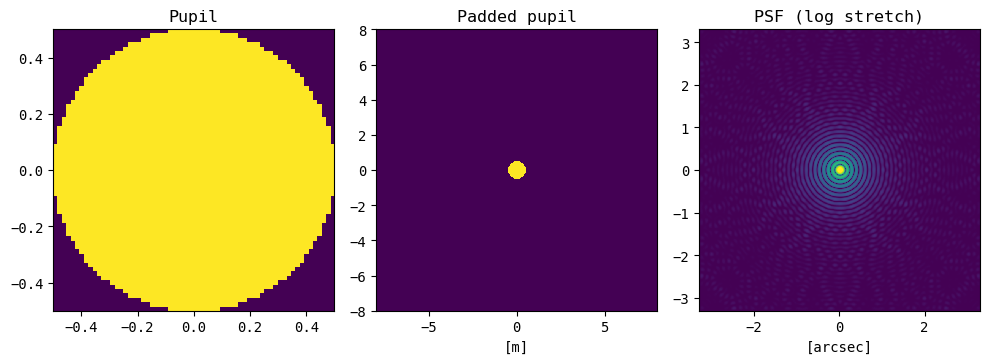

In [13]:
# --- 1.2 Diffraction-limited PSF of a circular aperture -----------------
N   = 64              # pupil pixels across the array
D   = 1.0              # telescope diameter [m]
delta_x = D / N        # m/pxl
pad_factor = 16                # zero-padding factor -> oversampled PSF

pupil = aotools.circle(D/delta_x/2, N)

# Place the pupil in a larger (padded) array -> finer sampling in the focal plane.
# The pupil is CENTRED in the padded array (padding equally distributed on all sides).
# NB: this leaves the PSF unchanged (|ft2|^2 is shift-invariant) — it only makes the
# padded array symmetric about the origin.
padded_pupil = np.zeros((N*pad_factor, N*pad_factor))
p0 = (N*pad_factor - N) // 2          # offset so the pupil lands in the centre
padded_pupil[p0:p0+N, p0:p0+N] = pupil

# E-field in the pupil plane
wavefront = padded_pupil * np.exp(1j*0)  # flat wavefront; the np.exp is not necessary, but included for clarity
# E-field in the focal plane
E_focal = aotools.ft2(wavefront, delta=delta_x)
# Pupil -> focal plane
psf = np.abs(E_focal)**2
psf /= psf.max()



# Focal-plane scales
fpxl_rad    = WAVELENGTH / (N*pad_factor*delta_x)     # rad per focal-plane pixel
fpxl_arcsec = fpxl_rad * 206265                # arcsec per focal-plane pixel
print(f'focal-plane pixel scale: {fpxl_arcsec*1000:.2f} mas/pxl')
print(f'diffraction limit lambda/D = {WAVELENGTH/D*206265*1000:.1f} mas')



fig, ax = plt.subplots(1, 3, figsize=(10, 4.5))
im0 = ax[0].imshow(pupil, extent=[-D/2, D/2, -D/2, D/2])
ax[0].set_title('Pupil'); ax[1].set_xlabel('[m]')

pad_ext = N*pad_factor*delta_x/2      # padded-array half-size [m]
im0 = ax[1].imshow(padded_pupil, extent=[-pad_ext, pad_ext, -pad_ext, pad_ext])
ax[1].set_title('Padded pupil')
ax[1].set_xlabel('[m]')

ext = N*pad_factor/2 * fpxl_arcsec
im1 = imshow_norm(psf, stretch=LogStretch(a=1e4), interval=PercentileInterval(99.95),
                  ax=ax[2], extent=[-ext, ext, -ext, ext])
ax[2].set_title('PSF (log stretch)'); ax[2].set_xlabel('[arcsec]')
plt.tight_layout()

### 1.3 Measuring a PSF
**First zero, EE50, FWHM**

Because the Airy pattern is circularly symmetric, `aotools.azimuthal_average` reduces it to a 1-D profile. From it we measure the **first zero** and the **encircled energy** (`aotools.encircled_energy`), then the **FWHM** 

TODO: remove MTF ?
>and the **MTF** — the modulus of the FT of the PSF — which cuts off at $D/\lambda$ cycles per radian: no spatial frequency beyond the telescope aperture gets through.

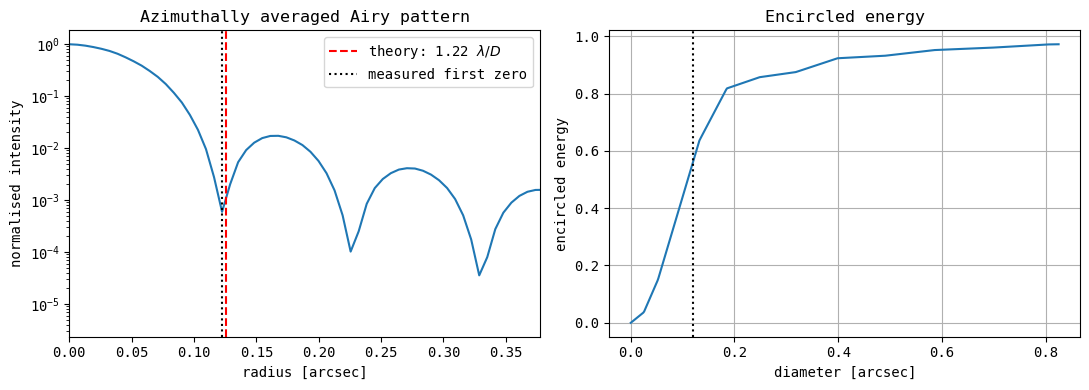

FWHM = 0.103 arcsec = 1.00 lambda/D  (Airy: 1.03)
first Airy zero : measured 0.122 arcsec | theory 0.126 arcsec
EE50 diameter   : 0.121 arcsec = 1.17 lambda/D (Airy: ~1.1)


In [14]:
# --- 1.3 Measuring the Airy pattern -------------------------------------
# The PSF is circularly symmetric -> azimuthal average (aotools.azimuthal_average)
cc = psf.shape[0]//2
box=128
azi = aotools.azimuthal_average(psf[cc-box:cc+box, cc-box:cc+box])
r_arcsec = np.arange(len(azi)) * fpxl_arcsec


# First zero of the Airy pattern: theory 1.22 lambda/D
first_zero = 1.22 * WAVELENGTH / D * 206265   # arcsec
# locate the measured first zero: the first LOCAL minimum of the profile
# (searching a window for the global min would jump to the 2nd/3rd zero)
i_th = np.argmin(np.abs(r_arcsec - first_zero))
i_zero = int(np.argmax(np.diff(azi[:i_th+8]) > 0))   # first index where the profile rises again

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(r_arcsec, azi)
ax[0].axvline(first_zero, color='r', ls='--', label='theory: 1.22 $\\lambda/D$')
ax[0].axvline(r_arcsec[i_zero], color='k', ls=':', label='measured first zero')
ax[0].set_xlabel('radius [arcsec]'); ax[0].set_ylabel('normalised intensity')
ax[0].semilogy()
ax[0].set_title('Azimuthally averaged Airy pattern')
ax[0].legend(); ax[0].set_xlim(0, 3*first_zero)



# Encircled energy curve (aotools.encircled_energy)
box=128
diam, ee = aotools.encircled_energy(psf[cc-box:cc+box, cc-box:cc+box], eeDiameter=False)
ee50 = aotools.encircled_energy(psf, fraction=0.5)

ax[1].plot(diam*fpxl_arcsec, ee)
ax[1].axvline(ee50*fpxl_arcsec, color='k', ls=':', label='EE50 diameter')
ax[1].set_xlabel('diameter [arcsec]'); ax[1].set_ylabel('encircled energy')
ax[1].set_title('Encircled energy'); ax[1].grid(True)
plt.tight_layout()
plt.show()

# FWHM from the azimuthal average
# azi = aotools.azimuthal_average(psf)
half = np.where(azi < azi.max()/2)[0]
fwhm_px = 2*half[0]
print(f'FWHM = {fwhm_px*fpxl_rad*206265:.3f} arcsec = {fwhm_px*fpxl_rad/WAVELENGTH*D:.2f} lambda/D  (Airy: 1.03)')
print(f'first Airy zero : measured {r_arcsec[i_zero]:.3f} arcsec | theory {first_zero:.3f} arcsec')
print(f'EE50 diameter   : {ee50*fpxl_arcsec:.3f} arcsec = {ee50*fpxl_rad/WAVELENGTH*D:.2f} lambda/D (Airy: ~1.1)')


### Exercise 1 — pupils and diffraction
1. The diffraction limit $\lambda/D$ for $D = 1$ m at $\lambda = 500$ nm is $\approx 0.1$ arcsec. What is it at $\lambda = 2.2\mu m$ (K band)? 
2. **Padding:** change `pad_factor` (4, 8, 16). 
   1. What happens to the PSF pixel scale (`fpxl_arcsec`) and to the *measured* first zero? 
   2. What happen to the encircled enery
   3. The function ``azimuthal_average`` is sampled every pixel. More advanced routine can do subpixel sampling, such as ``Photutils.profiles.RadialProfile``. See the cell below and compare it to what you have done and learned so far. 
3. Compute the PSF of an **annular** pupil (a disk minus a smaller disk) or a pupil with spider vanes, and measure its FWHM and EE50. How do they change?
   1. Compute the radial profiles and compare them to the circular pupil




/opt/homebrew/Caskroom/miniforge/base/envs/numpy_arm/lib/python3.12/site-packages/asdf/asdf.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


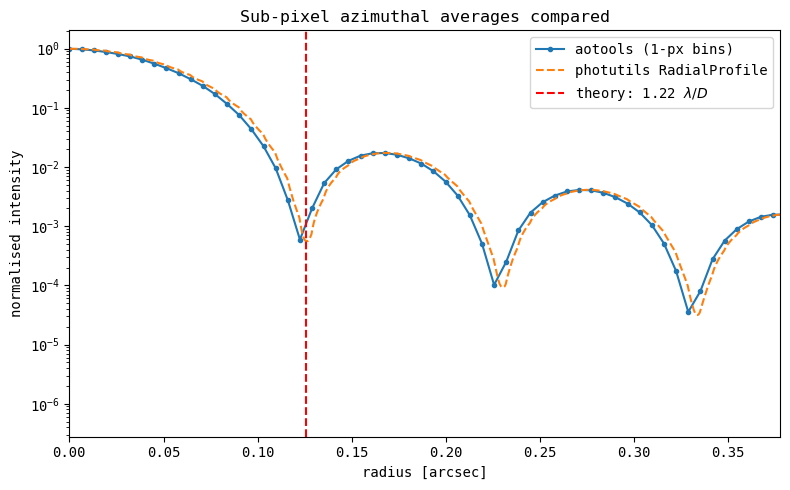

In [15]:
# --- Exercice 2.3: Sub-pixel azimuthal average with photutils ----------------------------
# photutils.profiles.RadialProfile uses fractional-pixel-weighted annuli,
# which gives a true sub-pixel azimuthal average (each pixel contributes
# to annuli proportionally to its fractional overlap).

from photutils.profiles import RadialProfile

# RadialProfile expects the center in (x, y) pixel coordinates
box=128
data = psf[cc-box:cc+box, cc-box:cc+box]
ny, nx = data.shape   # rows, cols
center_xy = ((nx-1)/2, (ny-1)/2)   # (x, y) = (col, row) of the PSF peak
bin_width = 0.1   # pixels
r_max = np.hypot(nx/2, ny/2)       # max radius: centre to farthest corner
bins = np.arange(0, r_max + bin_width, bin_width)

rp = RadialProfile(data, center_xy, radii=bins, error=None)
azi_phot = rp.profile
# Compute bin centres ourselves — rp.radius length can differ from
# rp.profile depending on the photutils version
bin_centers = 0.5 * (bins[:-1] + bins[1:])
n = min(len(bin_centers), len(azi_phot))
r_phot_arcsec = bin_centers[:n] * fpxl_arcsec   # [pixels] -> [arcsec]
azi_phot = azi_phot[:n]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_arcsec, azi, 'o-', ms=3, label='aotools (1-px bins)')
ax.plot(r_phot_arcsec, azi_phot, '--', lw=1.5, label='photutils RadialProfile')
ax.axvline(first_zero, color='r', ls='--', label='theory: 1.22 $\\lambda/D$')
ax.set_xlabel('radius [arcsec]'); ax.set_ylabel('normalised intensity')
ax.semilogy()
ax.set_title('Sub-pixel azimuthal averages compared')
ax.legend(); ax.set_xlim(0, 3*first_zero)
plt.tight_layout()
plt.show()

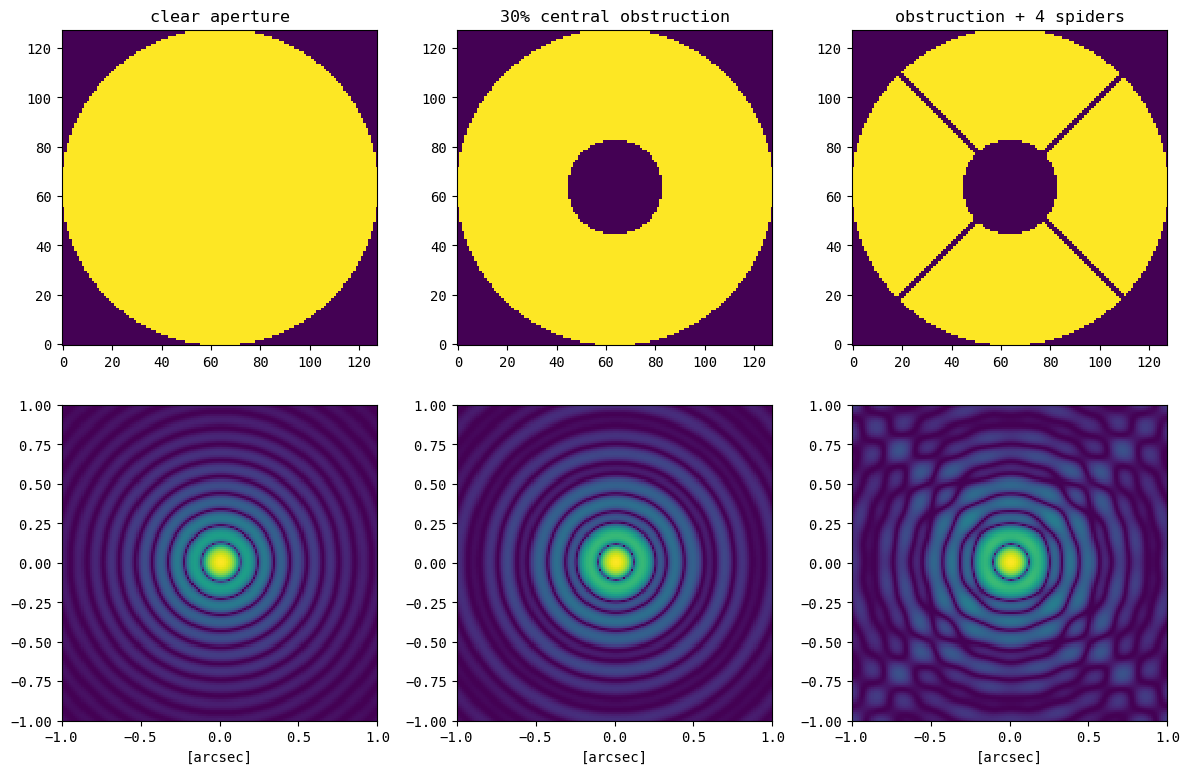

In [16]:
# --- Exercise 3: annular pupil and spider vanes --------------------------
N = 128; D = 1.0; delta_x = D/N; PAD = 8

def make_pupil(N, eps=0.0, n_spiders=0, spider_width=0.02):
    '''Circular pupil with a central obstruction (eps) and spider vanes.'''
    n_spiders = n_spiders // 2
    pupil = aotools.circle(N/2, N)
    if eps > 0:
        pupil = pupil - aotools.circle(eps*N/2, N)
    if n_spiders > 0:
        # Coordinate grids centred on the pupil (origin at the array centre)
        yy, xx = np.mgrid[0:N, 0:N] - N/2
        r = np.hypot(xx, yy)          # radial distance from centre [pixels]
        theta = np.arctan2(yy, xx)   # azimuthal angle [radians]
        # Each loop iteration creates a pair of opposite vanes (a spider is
        # two vanes 180° apart), so n_spiders was halved above.
        for k in range(n_spiders):
            # Vane axis angle: start at 45°, evenly spaced around the pupil
            ang = np.deg2rad(45 + k*180/n_spiders)
            # Perpendicular distance from each pixel to the vane axis.
            # r*sin(theta - ang) is the cross-product form: it gives the
            # shortest distance from the point (r, theta) to the line
            # through the origin at angle `ang`.
            d_perp = np.abs(r*np.sin(theta - ang))   # distance to the vane axis
            # Mask out pixels within half the spider width of the vane axis.
            # spider_width is a fraction of the pupil diameter.
            pupil = pupil * (d_perp > spider_width*N/2)
    return pupil

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
cases = [(0.0, 0, 'clear aperture'),
         (0.3, 0, '30% central obstruction'),
         (0.3, 4, 'obstruction + 4 spiders')]
for col, (eps, n_sp, label) in enumerate(cases):
    pupil = make_pupil(N, eps=eps, n_spiders=n_sp)
    padded = np.zeros((N*PAD, N*PAD)); padded[:N, :N] = pupil
    psf = np.abs(aotools.ft2(padded, delta=delta_x))**2
    psf /= psf.max()
    ext = N*PAD/2 * WAVELENGTH/(N*PAD*delta_x) * 206265
    ax[0, col].imshow(pupil); ax[0, col].set_title(label)
    imshow_norm(psf, stretch=LogStretch(a=1e4), ax=ax[1, col],
                 extent=[-ext, ext, -ext, ext])
    hfov=1
    ax[1, col].set_xlim(-hfov, hfov)
    ax[1, col].set_ylim(-hfov, hfov)
    ax[1, col].set_xlabel('[arcsec]')
plt.tight_layout()


# 2. Optical aberrations: Zernike modes (~25 min)
- Introduce Zernike polynomials
- Generate aberrated PSF
- Aberrations and Strehl ratio / Maréchal approximation

<br>

Any wavefront over a circular pupil can be decomposed into **Zernike polynomials** — a complete set of continuous functions orthogonal over a unit circle and the standard basis of optical aberrations. 

`aotools` uses the **Noll indexing** ($j = 1, 2, 3, \dots$: piston, tip, tilt, defocus, astigmatisms, coma, …) with **unit-RMS-over-the-pupil normalisation** by default (`norm='noll'`; also `'p2v'`, `'rms'`).


The wavefront can be written as
$$ W(x,y) = \sum_{j=0}^{J} a_j Z_j (x,y) $$
with $a_j$ the Zernike coefficients and $Z_j$ the Zernike polynomial

The wavefront variances equals the sum of the square of its coefficients (excluding piston)
$$\sigma_{\phi}^2 = \sum_{j=1}^{\infty} a_j^2$$

<br>

  

### 2.1 Zernike mode generation

In `aotools`, the simplest way to generate Zernike modes is to use the `aotools.ZernikeArray` function. This generates all of the Zernike modes up to a certain $J$ index.

Alternative are `aotools.zernike_nm` or `aotools.zernike_noll` to get a single mode using either its radial and azimuthal index $(n,m)$, or using its Noll index $j$.

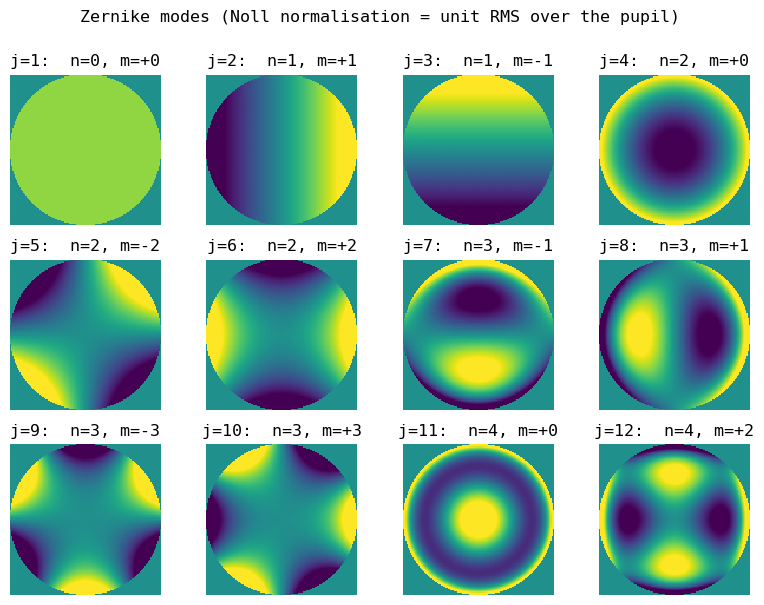

In [17]:
# --- 2.1 The first Zernike modes -----------------------------------------
N = 128
n_modes = 12
Zs = aotools.zernikeArray(n_modes, N)   # Zs[j-1] = Zernike mode j (Noll)

fig, ax = plt.subplots(3, 4, figsize=(8, 6))
for j in range(1, n_modes+1):
    n, m = aotools.zernIndex(j)
    a = ax.flat[j-1]
    a.imshow(Zs[j-1],  vmin=-1.5, vmax=1.5)
    a.set_title(f'j={j}:  n={n}, m={m:+d}')
    a.axis('off')
fig.suptitle('Zernike modes (Noll normalisation = unit RMS over the pupil)', y=1.0)
plt.tight_layout()


j -> [n, m]:
  j=1: [0, 0]
  j=2: [1, 1]
  j=3: [1, -1]
  j=4: [2, 0]
  j=5: [2, -2]
  j=6: [2, 2]
  j=7: [3, -1]
coma and astigmatism arrays: (128, 128) (128, 128)


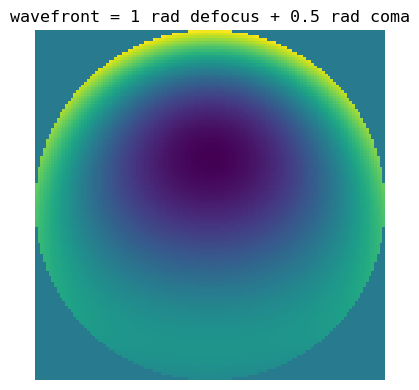

In [18]:
# --- 2.2 Single modes, index conventions, building a wavefront -----------
print('j -> [n, m]:')
for j in range(1, 8):
    print(f'  j={j}: {aotools.zernIndex(j)}')

# A single mode, two ways of asking for it
coma  = aotools.zernike_noll(7, N)       # j=7 is coma
astig = aotools.zernike_nm(2, 2, N)      # n=2, m=+2 is (one) astigmatism
print('coma and astigmatism arrays:', coma.shape, astig.shape)

# Build a wavefront from a coefficient vector (coefficients in radians, Noll norm)
coeffs = np.zeros(n_modes)
coeffs[3] = 1.0     # j=4: defocus, 1 rad rms
coeffs[6] = 0.5     # j=7: coma, 0.5 rad rms
wavefront = aotools.phaseFromZernikes(coeffs, N)

# fig, ax = plt.subplots(1, 2, figsize=(10, 4))
# ax[0].imshow(wavefront)
# ax[0].set_title('wavefront = 1 rad defocus + 0.5 rad coma'); ax[0].axis('off')
# ax[1].imshow(np.angle(np.exp(1j*wavefront)))
# ax[1].set_title('wrapped phase'); ax[1].axis('off')
# plt.tight_layout()
plt.figure(figsize=(5, 4))
plt.imshow(wavefront)
plt.title('wavefront = 1 rad defocus + 0.5 rad coma')
plt.axis('off')
plt.tight_layout()

### 2.2 Aberrated PSFs and the Strehl ratio


The quality of an aberrated PSF is summarised by the **Strehl ratio** 
$$S = \dfrac{\text{peak of the aberrated PSF}}{\text{ peak of the diffraction-limited PSF}}$$
For small aberrations the **Maréchal approximation** gives $S \approx e^{-\sigma_\phi^2}$ with $\sigma_\phi$ the wavefront rms in radians.

As a reminder the PSF is $|\mathcal{F}\{P \exp{j \phi}\}|^2$, with $\phi$ the phase aberrations expressed in radians.


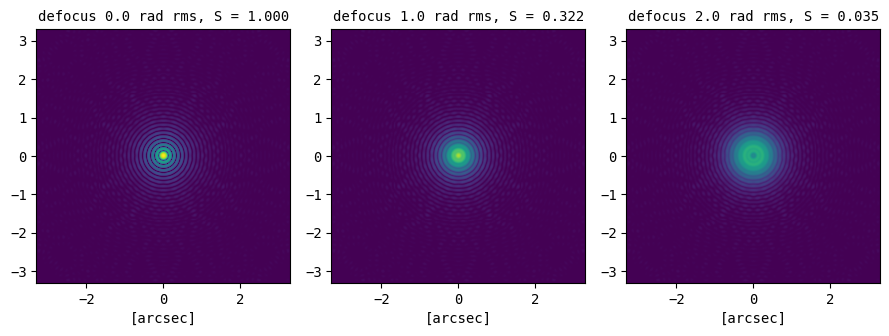

In [19]:
# --- 2.3 What aberrations do to the PSF -----------------------------------
N = 64; D = 1.0; delta_x = D/N; PAD = 4
pupil = aotools.circle(N/2, N)
padded = np.zeros((N*PAD, N*PAD), dtype=complex); padded[:N, :N] = pupil
psf_dl = np.abs(aotools.ft2(padded, delta=delta_x))**2
peak_dl = psf_dl.max()

Z_defocus = aotools.zernike_noll(4, N)   # unit RMS over the pupil
coefficients = [0.0, 1.0, 2.0]

fig, ax = plt.subplots(1, 3, figsize=(9, 4))
ext = N*PAD/2 * WAVELENGTH/(N*PAD*delta_x) * 206265   # arcsec

for a, amp in enumerate(coefficients):
    padded[:N, :N] = pupil * np.exp(1j*amp*Z_defocus)
    psf = np.abs(aotools.ft2(padded, delta=delta_x))**2
    psf /= peak_dl                      # all normalised to the diffraction-limited peak
    imshow_norm(psf, stretch=LogStretch(a=1e4), ax=ax[a],
                extent=[-ext, ext, -ext, ext], vmin=0, vmax=1)
    ax[a].set_title(f'defocus {amp} rad rms, S = {psf.max():.3f}', fontsize=10)
    ax[a].set_xlabel('[arcsec]')
plt.tight_layout()

In [20]:
# # --- 2.4 Strehl ratio vs Maréchal approximation ---------------------------
# N = 64; D = 1.0; delta_x = D/N; PAD = 4
# pupil = aotools.circle(N/2, N)
# padded = np.zeros((N*PAD, N*PAD), dtype=complex); padded[:N, :N] = pupil
# psf_dl = np.abs(aotools.ft2(padded, delta=delta_x))**2
# peak_dl = psf_dl.max()

# Z_defocus = aotools.zernike_noll(4, N)   # unit RMS over the pupil

print(' defocus amp [rad] | sigma^2 [rad^2] | Strehl (measured) | (Maréchal) exp(-sigma^2) ')
for amp in [0.3, 0.6, 1.0, 1.5, 2.0]:
    # Complex electric field in the pupil plane: pupil * exp(i*wavefront)
    padded[:N, :N] = pupil * np.exp(1j*amp*Z_defocus)
    # PSF: |.|ˆ2 of the Fourier transform of the pupil field
    psf = np.abs(aotools.ft2(padded, delta=delta_x))**2
    strehl = psf.max()/peak_dl
    print(f'        {amp:4.1f}       |      {amp**2:5.2f}      |        {strehl:.4f}       |          {np.exp(-amp**2):.4f}')

print()
print('Note: Maréchal is accurate for sigma^2 <~ 1 rad^2 and degrades for stronger aberrations.')

 defocus amp [rad] | sigma^2 [rad^2] | Strehl (measured) | (Maréchal) exp(-sigma^2) 
         0.3       |       0.09      |        0.9126       |          0.9139
         0.6       |       0.36      |        0.6862       |          0.6977
         1.0       |       1.00      |        0.3219       |          0.3679
         1.5       |       2.25      |        0.0748       |          0.1054
         2.0       |       4.00      |        0.0351       |          0.0183

Note: Maréchal is accurate for sigma^2 <~ 1 rad^2 and degrades for stronger aberrations.


### Exercise 2 — aberrations and wavefront error
1. A wavefront has $\sigma_\phi = 1$ rad rms at 500 nm. What is the Strehl ratio (Maréchal)? What OPD rms does this correspond to in nm?
2. Using the Zernike basis, introduce different modes (other than focus) alone or in combination to visually experience the PSF shapes
3. Compare PSF with positive and negative defocus (or any other mode with even radial order $n$)? And now compare  PSF with positive and negative coma ($j=7$; or any other mode with odd radial order) ? 
4. Generate an aberrated PSFs with the combination of aberration of your choice, and compute the radial profile, the fwhm, and the EE50d

# 3. Atmospheric turbulence (~10 min)
- Fried parameter and seeing ($\epsilon = 0.98\,\lambda/r_0$), **$r_0 \propto \lambda^{6/5}$** scaling
- Cn2 profile
- coherence time, isoplanatic angle


TODO: remove Rytov variance

In [21]:
# --- 3.1 r0 <-> seeing <-> Cn2, and the wavelength scaling ---------------
r0_500 = 0.15   # m, at 500 nm (typical for a good site)
seeing = aotools.r0_to_seeing(r0_500)          # arcsec
cn2    = aotools.r0_to_cn2(r0_500)             # integrated Cn^2, m^(-2/3), single layer

print(f'r0 = {r0_500} m at 500 nm  ->  seeing = {seeing:.2f} arcsec,  Cn2 = {cn2:.3e} m^(-2/3)')
print(f'round trip: r0 from seeing = {aotools.seeing_to_r0(seeing):.4f} m, '
      f'r0 from Cn2 = {aotools.cn2_to_r0(cn2):.4f} m')

# r0 scales as lambda^(6/5): the same Cn2 gives a larger r0 at longer wavelengths
print()
print(' lambda [um] | r0 [m] | seeing [arcsec]')
for lam_um in [0.5, 0.8, 1.25, 1.65, 2.2]:
    lam = lam_um*1e-6
    r0_lam = aotools.cn2_to_r0(cn2, lamda=lam)
    print(f'    {lam_um:4.2f}    | {r0_lam:.3f}  | {aotools.r0_to_seeing(r0_lam, lamda=lam):.2f}')


r0 = 0.15 m at 500 nm  ->  seeing = 0.67 arcsec,  Cn2 = 3.535e-13 m^(-2/3)
round trip: r0 from seeing = 0.1500 m, r0 from Cn2 = 0.1500 m

 lambda [um] | r0 [m] | seeing [arcsec]
    0.50    | 0.150  | 0.67
    0.80    | 0.264  | 0.61
    1.25    | 0.450  | 0.56
    1.65    | 0.629  | 0.53
    2.20    | 0.888  | 0.50


In [22]:
# --- 3.2 Coherence time, isoplanatic angle ----------------
# A 3-layer Cn2 profile (fractional r0 per layer, altitudes in m)
h     = np.array([0., 5000., 10000.])
frac  = np.array([0.7, 0.2, 0.1])                  # fraction of total r0^(-5/3) per layer; total = 1.0
cn2_profile = aotools.r0_to_cn2(r0_500) * frac     # m^(-2/3) per layer
wind  = np.array([10., 15., 25.])                  # m/s per layer

tau0  = aotools.coherenceTime(cn2_profile, wind, lamda=WAVELENGTH)      # [s]
theta0 = aotools.isoplanaticAngle(cn2_profile, h, lamda=WAVELENGTH)     # [arcsec] already!

print(f'coherence time  tau0 at {WAVELENGTH*1e6:.1f} um = {tau0*1000:.2f} ms')
print(f'isoplanatic angle theta0 at {WAVELENGTH*1e6:.1f} um = {theta0:.2f} arcsec')


coherence time  tau0 at 0.5 um = 3.62 ms
isoplanatic angle theta0 at 0.5 um = 2.89 arcsec


### Exercise 3

1. From the table: by what factor does $r_0$ grow between 0.5 µm and 2.2 µm? Check against $\lambda^{6/5}$
2.  Compare the coherence time and the isoplanatic angle at different wavelengths
3.  The Fried parameter and the coherence time increase with wavelength. Compare the values at 0.5 µm and 2.2 µm. What are the impact on an AO system ?



# 4. Generate phase screens (~20 min)

- Generate Kolmogorov / von Kármán phase screens (`ft_phase_screen`; sub-harmonics with `ft_sh_phase_screen`)
- Validation: Zernike power spectrum <-> Noll 1976; phase structure function (Exercise 4)
- Infinite (extruded) phase screens and the outer scale $L_0$ — the method used by soapy in Part 2


### 4.1 Your first phase screen

`aotools.turbulence.phasescreen.ft_phase_screen(r0, N, delta, L0, l0)` generates one Kolmogorov / von Kármán phase screen (in **radians**) by filtering white noise with the turbulence power spectrum in Fourier space. Parameters: `r0` (Fried parameter [m]), `N` (pixels across), `delta` (m/px), `L0` (outer scale [m]), `l0` (inner scale [m]).

Generate one screen for a 1 m telescope ($r_0 = 0.32m$ at 500 nm, $L_0 = 100m$, $l_0 = 1 mm$). Recall the convention: $\mathrm{OPD} = \phi \times \lambda/2\pi$.


screen shape: (64, 64) | phase in radians
phase rms over the screen: 5.93 rad = 472 nm OPD rms


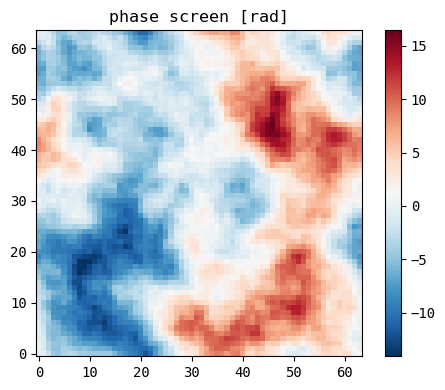

In [51]:
# --- 4.1 Your first phase screen -------------------------------------------
# Telescope D = 1 m on 64 px; turbulence r0 = 0.32 m (at 500 nm), L0 = 100 m, l0 = 1 mm
nx_size = 64
D = 10.0
pxl_scale = D/nx_size
r0 = 0.32
L0 = 100.
l0 = 1e-3

phase_screen = phasescreen.ft_phase_screen(r0, nx_size, pxl_scale, L0, l0)

print('screen shape:', phase_screen.shape, '| phase in radians')
print(f'phase rms over the screen: {phase_screen.std():.2f} rad '
      f'= {phase_screen.std()*WAVELENGTH/2/np.pi*1e9:.0f} nm OPD rms')

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(phase_screen, cmap='RdBu_r')
ax.set_title('phase screen [rad]'); fig.colorbar(im, ax=ax)
plt.tight_layout()


### 4.2 Zernike power spectrum vs Noll (1976)

Projecting screens onto the Zernike basis should reproduce the **Noll (1976)** sequence $\langle a_j^2\rangle = b_j\,(D/r_0)^{5/3}$ (rad²), with $b_2 = b_3 = 0.448$ (tip/tilt), $b_4 = b_5 = b_6 = 0.0232$ (defocus, astigmatism), … 
The sequence is shipped with this notebook as `noll.fits` (same directory; the file originates from the `aotools_tests` repository); its diagonal gives $b_j$ for $j = 2, 3, 4, \dots$ (piston excluded).

Projection onto unit-RMS Zernikes (`aotools.zernikeArray` returns unit-RMS modes): $a_j = \sum \phi\, Z_j / N_\mathrm{px}$.

> A screen the size of the pupil **underestimates tip/tilt** (scales $> D$ are missing) — sub-harmonics (Exercise 4) or infinite phase screens (4.3) recover it partly.


first values (j=2,3,4,5,6): [0.44863 0.44863 0.0232  0.0232  0.0232 ]


  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:00<00:00, 2316.53it/s]

Note the underestimate of tip/tilt (j=2,3) and the aliasing scatter at high j.
tip/tilt (j=2,3) measured/Noll: [0.04 0.62]


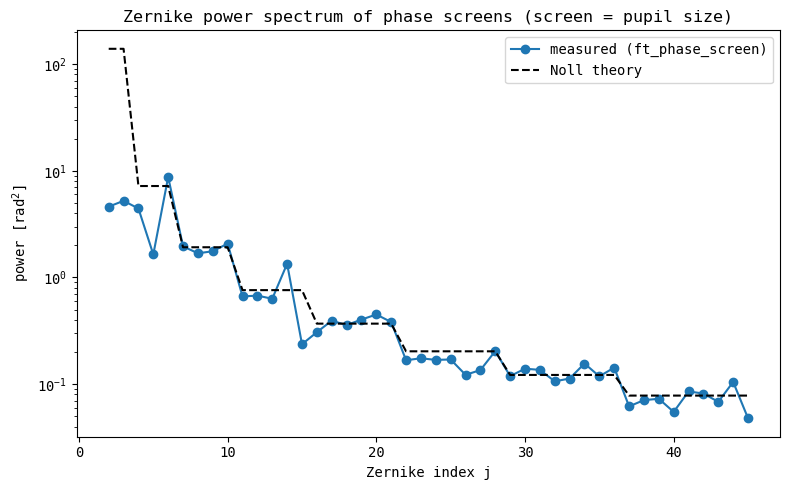

In [52]:
# --- 4.2 Zernike power spectrum vs Noll (1976) -------------------------------
# Noll sequence b_j from noll.fits (shipped with this notebook, same directory):
# its diagonal gives b_j for j = 2,3,4,... in units of (D/r0)^(5/3) rad^2
from astropy.io import fits

noll_b = fits.getdata('noll.fits').diagonal()   # noll_b[j-2] = b_j for Zernike index j >= 2
print('first values (j=2,3,4,5,6):', np.round(noll_b[:5], 5))

# Zernike power spectrum of ft_phase_screen screens (same setup as 4.1)
# cf. assets/aotools_tests/workshop/2_phase_screens.ipynb
n_zerns = 45
n_scrns = 100
Zs = aotools.zernikeArray(n_zerns, nx_size)     # unit-RMS Zernikes
z_coeffs = np.zeros((n_scrns, n_zerns))         
for n in tqdm(range(n_scrns)):
    scrn = phasescreen.ft_phase_screen(r0, nx_size, pxl_scale, L0, l0)
    z_coeffs[n] = (scrn * Zs).sum((-1, -2)) / Zs[0].sum()   # a_j = sum(phi*Z_j)/N_px
z_var = z_coeffs.var(0)[1:]  # variance of Zernike modes; skipping piston

# Noll theory: <a_j^2> = b_j (D/r0)^(5/3)
noll_theory = noll_b[:n_zerns-1] * (D/r0)**(5/3)  # j=1 (piston) = 0

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(2, n_zerns+1), z_var, 'o-', label='measured (ft_phase_screen)')
ax.plot(range(2, n_zerns+1), noll_theory, 'k--', label='Noll theory')
ax.set_yscale('log')
ax.set_xlabel('Zernike index j'); ax.set_ylabel('power [rad$^2$]')
ax.set_title('Zernike power spectrum of phase screens (screen = pupil size)')
ax.legend()
plt.tight_layout()
print('Note the underestimate of tip/tilt (j=2,3) and the aliasing scatter at high j.')
print(f'tip/tilt (j=2,3) measured/Noll: {np.round(z_var[1:3]/noll_theory[1:3], 2)}')


### 4.3 Infinite phase screens and the outer scale $L_0$

**Infinite (extruded) phase screens** keep only a small window of phase and extend it row by row with `add_row()` (current map in `.scrn`, in radians) — constant memory, and the method **soapy** uses for its atmosphere in Part 2. With wind speed $v$, one `add_row()` is a time step $\Delta t = \delta_x/v$. 

We use them here for two checks: the Zernike spectrum vs Noll (the extruded screen contains scales $> D$, so tip/tilt is recovered), and the role of the outer scale $L_0$ (von Kármán suppresses scales $> L_0$; Noll assumes $L_0 \to \infty$).


<>:46: SyntaxWarning: invalid escape sequence '\i'
<>:46: SyntaxWarning: invalid escape sequence '\i'
/var/folders/y8/qwkl8q7s08l_x77m0b624hm40000gn/T/ipykernel_8393/3382515478.py:46: SyntaxWarning: invalid escape sequence '\i'
  ax.plot(range(2, n_zerns+1), noll_theory, 'k--', label='Noll theory ($L_0 \to \infty$)')


current map .scrn: (64, 64) [rad]


L0 = 10 m: 100%|██████████| 25/25 [00:01<00:00, 22.77it/s]


L0 =     10 m: tip/tilt (j=2,3) measured/Noll = [0.01 0.02],  screen rms = 5.89 rad


L0 = 25 m: 100%|██████████| 25/25 [00:01<00:00, 24.08it/s]


L0 =     25 m: tip/tilt (j=2,3) measured/Noll = [0.06 0.07],  screen rms = 10.11 rad


L0 = 100 m: 100%|██████████| 25/25 [00:00<00:00, 26.44it/s]


L0 =    100 m: tip/tilt (j=2,3) measured/Noll = [0.15 0.15],  screen rms = 14.12 rad


L0 = 1000 m: 100%|██████████| 25/25 [00:00<00:00, 27.00it/s]


L0 =   1000 m: tip/tilt (j=2,3) measured/Noll = [0.22 0.23],  screen rms = 18.01 rad
Low-order power grows with L0 towards the Noll (L0 -> inf) curve;
the infinite screen also recovers the tip/tilt missing from a pupil-size screen (4.2).


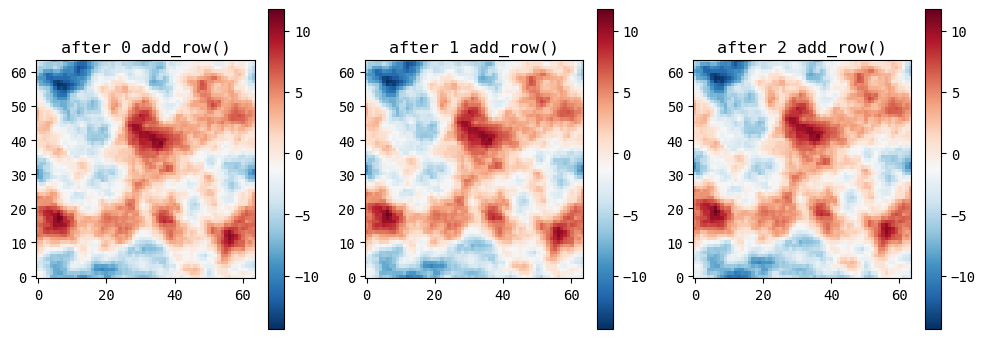

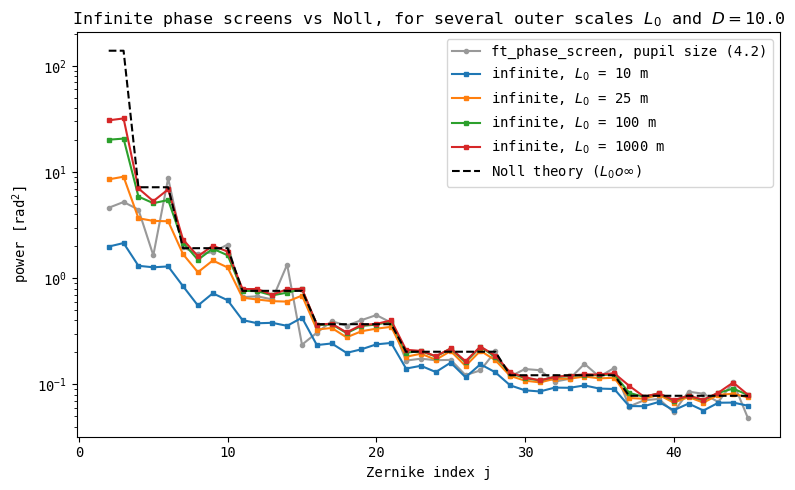

In [ ]:
# --- 4.3 Infinite phase screens: evolution, outer scale L0, Zernike vs Noll --
# One object, extruded row by row: the screen evolves (frozen flow)
inf_scrn = infinitephasescreen.PhaseScreenVonKarman(
    nx_size, pxl_scale, r0, L0, random_seed=1)
print('current map .scrn:', inf_scrn.scrn.shape, '[rad]')

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for k, a in enumerate(ax):
    if k > 0:
        inf_scrn.add_row()                     # one wind step of one pixel
    im = a.imshow(inf_scrn.scrn, cmap='RdBu_r')
    a.set_title(f'after {k} add_row()'); fig.colorbar(im, ax=a)
plt.tight_layout()

# Zernike spectra of evolved infinite screens for several outer scales, vs Noll.
# Successive add_row() screens are correlated: go in all directions to
# decorrelate them quickly (cf. fried_infinate_phase_screens.ipynb).
n_tests, n_steps = 25, 200
L0_list = [10., 25., 100., 1e3]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(2, n_zerns+1), z_var, 'o-', ms=3, color='0.6',
        label='ft_phase_screen, pupil size (4.2)')

for L0_i in L0_list:
    z_coeffs = np.zeros((n_tests, n_steps, n_zerns))
    for n in tqdm(range(n_tests), desc=f'L0 = {L0_i:g} m'):
        # ps = infinitephasescreen.PhaseScreenKolmogorov(
            # nx_size, pxl_scale, r0, L0_i, random_seed=n, stencil_length_factor=8)
        ps = infinitephasescreen.PhaseScreenVonKarman(
            nx_size, pxl_scale, r0, L0_i, random_seed=n)
        for i in range(n_steps):
            ps.add_row()
            scrn = ps.scrn
            if n % 4 == 1:   scrn = scrn.T
            elif n % 4 == 2: scrn = scrn[::-1]
            elif n % 4 == 3: scrn = scrn[::-1].T
            z_coeffs[n, i] = (scrn * Zs).sum((-1, -2)) / Zs[0].sum()
            
    zv = z_coeffs.var(1).mean(0)[1:] # variance of the Zernike coefficients, skipping piston
    
    ax.plot(range(2, n_zerns+1), zv, 's-', ms=3, label=f'infinite, $L_0$ = {L0_i:g} m')
    print(f'L0 = {L0_i:6g} m: tip/tilt (j=2,3) measured/Noll = '
          f'{np.round(zv[0:2]/noll_theory[0:2], 2)},  screen rms = {ps.scrn.std():.2f} rad')
    
ax.plot(range(2, n_zerns+1), noll_theory, 'k--', label='Noll theory ($L_0 \to \infty$)')
ax.set_yscale('log'); ax.set_xlabel('Zernike index j'); ax.set_ylabel('power [rad$^2$]')
ax.set_title(f'Infinite phase screens vs Noll, for several outer scales $L_0$ and $D=${D:.0f}m')
ax.legend()
plt.tight_layout()
print('Low-order power grows with L0 towards the Noll (L0 -> inf) curve;')
print('the infinite screen also recovers the tip/tilt missing from a pupil-size screen (4.2).')


### Exercise 4 — phase screens

1. **Wrapped phase.** Plot the wrapped phase `np.angle(np.exp(1j*phase_screen))` . Where do the $2\pi$ jumps appear, and what OPD do they correspond to at 500 nm? Why does wrapping matter for a DM or a WFS?
2. Compute the total wavefront error given by your phase screens (use `zv`) and compare it to Noll theory (use `noll_theory`) for a large outer scale? How do they compare?  


In-depth exercises:
1. **Sub-harmonics.** In the 4.2 cell, replace `ft_phase_screen` by `ft_sh_phase_screen(r0, nx_size, pxl_scale, L0, l0)`. How does it change the tip-tilt variance? Compare with a 4× larger screen (e.g. 256 px)
2. **Structure function.** On a screen much larger than the separations you probe (e.g. 4 m across, 256 px, $r_0 = 0.2m$, $L_0 = 25m$, $l_0 = 1mm$), measure $D_\phi(r) = \langle(\phi(x)-\phi(x+r))^2\rangle$ for distances $r = 2, 4, 8, 16, 32, 64$ px, averaged over ~30 screens (helper `measure_structure_function(phase, dist)`, or `aotools.calculate_structure_function`). Plot against `aotools.structure_function_kolmogorov(r, r0)` and `aotools.structure_function_vk(r, r0, L0)`; fit the power-law index between 4 and 32 px (expect $\approx 5/3$). What happens at the largest separations, and why?


In [55]:
# helper function for advanced exercise
def measure_structure_function(phase, dists):
    '''D_phi(r) = <(phi(x) - phi(x+r))^2>, averaged over the screen, for lags in pixels.'''
    return np.array([np.mean((phase[:-dist, :] - phase[dist:, :])**2) for dist in dists])


# 5. Imaging through turbulence (~15min)
The pupil-plane **complex field** is

$$U = P \cdot e^{i\phi}$$

and the PSF is $|\mathcal{F}\{U\}|^2$. Each phase screen gives an **instantaneous** PSF — a speckle pattern. Each speckle is approximately at the diffraction limit (FWHM $\sim \lambda/D$ ). A "slow" camera (/ long integration time) averages many speckles into the **long-exposure** PSF of size $\approx 0.98\,\lambda/r_0$.

D/r0 = 25.00  ->  strongly speckled instantaneous PSF


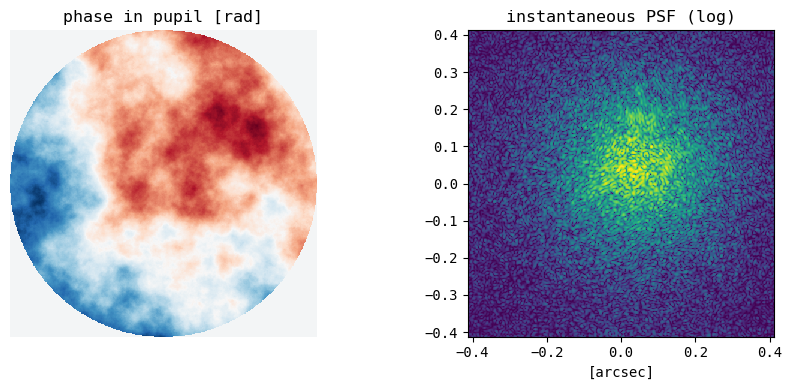

In [56]:
# --- 5.1 Instantaneous PSF through turbulence ------------------------------
nx_size = 128; D = 4.0; pxl_scale = D/nx_size
PAD = 4
r0 = 0.16; L0 = 100.; l0 = 1e-3
wavelength = 500E-9

pupil = aotools.circle(nx_size/2, nx_size)
pad_size = nx_size*PAD
padded_pupil = np.zeros((pad_size, pad_size), dtype=complex)
padded_pupil[:nx_size, :nx_size] = pupil

# phase screen the size of the padded pupil (oversized vs the 64 px pupil)
phase_screen = phasescreen.ft_sh_phase_screen(r0, pad_size, pxl_scale, L0, l0)

# complex field in the pupil plane
complex_field = padded_pupil * np.exp(1j*phase_screen)
psf_inst = np.abs(aotools.ft2(complex_field, delta=pxl_scale))**2

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(phase_screen*aotools.circle(pad_size/2, pad_size), cmap='RdBu_r')
ax[0].set_title('phase in pupil [rad]'); ax[0].axis('off')
imshow_norm(psf_inst/psf_inst.max(), stretch=LogStretch(a=1e4), interval=PercentileInterval(99.95),
            ax=ax[1], extent=[-ext, ext, -ext, ext])
ax[1].set_title('instantaneous PSF (log)'); ax[1].set_xlabel('[arcsec]')
plt.tight_layout()
print(f'D/r0 = {D/r0:.2f}  ->  strongly speckled instantaneous PSF')

100%|██████████| 1000/1000 [01:41<00:00,  9.85it/s]


long-exposure EE50 diameter = 0.655 arcsec (1.02 lambda/r0)
theory 0.98*lambda/r0       = 0.632 arcsec   |   diffraction limit lambda/D = 0.026 arcsec


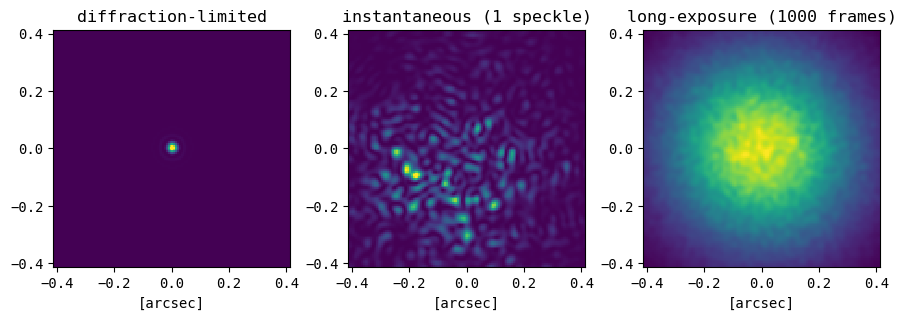

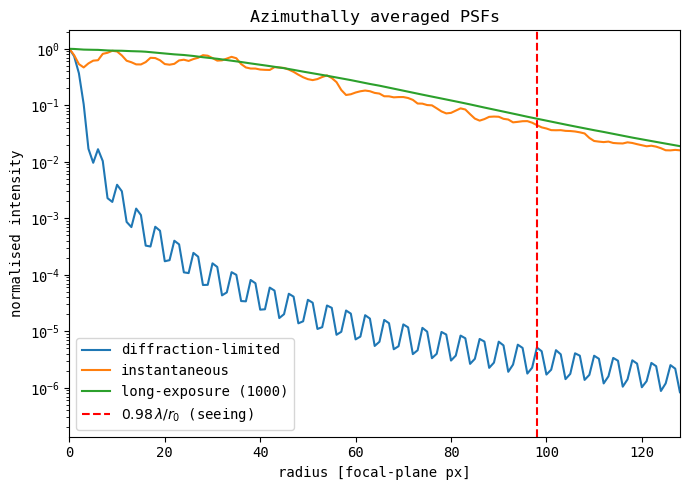

In [ ]:
# --- 5.2 Short-exposure vs long-exposure PSF --------------------------------
n_scrns = 1000
PAD = 4

psfs = np.zeros((n_scrns, pad_size, pad_size))
for n in tqdm(range(n_scrns)):
    scrn = phasescreen.ft_sh_phase_screen(r0, pad_size, pxl_scale, L0, l0)
    psfs[n] = np.abs(aotools.ft2(padded_pupil*np.exp(1j*scrn), delta=pxl_scale))**2
psf_long = psfs.mean(0)     # what a slow camera sees

# diffraction-limited reference
psf_dl = np.abs(aotools.ft2(padded_pupil, delta=pxl_scale))**2

fpxl = wavelength/(pad_size*pxl_scale)   # rad per focal-plane pixel
cut = int(pad_size/2 - nx_size/2); cut2 = int(pad_size/2 + nx_size/2)

fig, ax = plt.subplots(1, 3, figsize=(9, 4))
ext = nx_size/2 * fpxl * 206265
for a, (im, t) in enumerate([(psf_dl[cut:cut2, cut:cut2], 'diffraction-limited'),
                             (psfs[0][cut:cut2, cut:cut2], 'instantaneous (1 speckle)'),
                             (psf_long[cut:cut2, cut:cut2], f'long-exposure ({n_scrns} frames)')]):
    imshow_norm(im/im.max(),  interval=PercentileInterval(99.95), stretch=LinearStretch(),
                ax=ax[a], extent=[-ext, ext, -ext, ext])
    ax[a].set_title(t); ax[a].set_xlabel('[arcsec]')
plt.tight_layout()

# Radial profiles (-> azimuthal average)
azi_dl   = aotools.azimuthal_average(psf_dl)
azi_inst = aotools.azimuthal_average(psfs[0])
azi_long = aotools.azimuthal_average(psf_long)

# Plotting
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(azi_dl/azi_dl.max(), label='diffraction-limited')
ax.plot(azi_inst/azi_inst.max(), label='instantaneous')
ax.plot(azi_long/azi_long.max(), label=f'long-exposure ({n_scrns})')
ax.axvline(0.98*wavelength/r0/fpxl, color='r', ls='--', label='$0.98\\,\\lambda/r_0$ (seeing)')
ax.set_yscale('log'); ax.set_xlabel('radius [focal-plane px]'); ax.set_ylabel('normalised intensity')
ax.set_title('Azimuthally averaged PSFs'); ax.legend(); ax.set_xlim(0, nx_size)
plt.tight_layout()

# The long-exposure PSF is a diffraction-limited CORE + a seeing HALO: measuring
# the half-max from the peak only sees the core. The EE50 diameter is dominated
# by the halo and should match the seeing scale ~0.98*lambda/r0.
ee50 = aotools.encircled_energy(psf_long, 0.5)   # diameter [focal-plane px]
print(f'Measured long-exposure EE50 diameter = {ee50*fpxl*206265:.3f} arcsec '
      f'({ee50*fpxl/wavelength*r0:.2f} lambda/r0)')
print(f'Theory seeing FWHM: 0.98*lambda/r0       = {0.98*wavelength/r0*206265:.3f} arcsec   |   '
      f'diffraction limit lambda/D = {wavelength/D*206265:.3f} arcsec')

### Exercise 5 — imaging through turbulence

1. Change $r_0$ and observe the effect on the instantaneous and long-exposure PSFs. Try  $r_0$ close to the telescope diameter (better seeing) and try smaller values. 
2. To which well-known function does the long-exposure PSFs averages ?


# Summary and Beyond

### What we covered

| Section | Key takeaways |
|---|---|
| 1. Image formation | pupil to imager plane with `ft2`/`ift2`; focal-plane pixel $\lambda/(N\delta_x)$ rad; Airy first zero $1.22\,\lambda/D$; zero-pad the pupil to oversample the PSF |
| 2. Aberrations | Noll Zernikes (`zernikeArray`, `phaseFromZernikes`); Strehl $S \approx e^{-\sigma^2}$ (Maréchal, $\sigma$ in rad) |
| 3. Turbulence parameters | $r_0 \leftrightarrow$ seeing $\leftrightarrow C_n^2$; $r_0 \propto \lambda^{6/5}$; $\tau_0$, $\theta_0$ |
| 4. Phase screens | `ft_phase_screen` / `ft_sh_phase_screen` [rad]; Noll spectrum $b_j\,(D/r_0)^{5/3}$; a pupil-size screen underestimates tip/tilt; infinite screens (`PhaseScreenKolmogorov` + `add_row()`) and different $L_0$; fidelity of simulation |
| 5. Imaging through turbulence | $U = P\,e^{i\phi}$, PSF $= \|\mathcal{F}\{U\}\|^2$; instantaneous speckles vs long-exposure PSF $\approx 0.98\,\lambda/r_0$ |

### Things to remember
- Phase screens $\phi$ are in **radians**. $\mathrm{OPD} [\text{meters}] = \phi\,\lambda/2\pi$; $r_0$ quoted at 500 nm unless stated otherwise.
- Check the pixel scales before measuring anything: $\delta_f = 1/(N\delta_x)$, $\lambda/(N\delta_x)$ rad/px; zero-padding changes the sampling of $|FT|^2$, not the PSF itself.


### Beyond (in `aotools`) and bridge to Part 2 (Soapy)

| Topic | `aotools` entry points | Example notebook (in `aotools_tests/`) |
|---|---|---|
| Fresnel propagation, scintillation | `aotools.opticalpropagation` (`angularSpectrum`, `oneStepFresnel`, …) | `phase_screens/optical_propagation*.ipynb` |
| Wavefront sensing | `aotools.wfs` (`make_subaps_2d`, `findActiveSubaps`); centroiders (`centre_of_gravity`, `correlation_centroid`); `r0_from_slopes`; MMSE tomography in `turbulence.slopecovariance` | `wfs/sub_ap_mask.ipynb`, `image_processing/centroiders.ipynb` |
| Other wavefront bases | Karhunen–Loève (`make_kl`), elliptical-aperture Zernikes (`ZernikeEllipticalaperture`) | `phase_screens/kl_phase_screens.ipynb` |
| Multi-layer & time | `turbulence.profile_compression` (`equivalent_layers`, `GCTM`); `turbulence.temporal_ps` | `workshop/2_phase_screens.ipynb` |
| Photometry, image metrics | `aotools.astronomy` (`photons_per_mag`, …); `azimuthal_average`, `encircled_energy`, `image_contrast` | `image_processing/PSF.ipynb` |


**References**:
- Noll, R. J. (1976), "Zernike polynomials and atmospheric turbulence", JOSA 66, 207–211 — Zernike variances (shipped as `noll.fits`).
- Assemat, F., & Wilson, R. (2006); Fried, D. L. (2008) — infinite (extruded) phase screens, as implemented in `aotools.turbulence.infinitephasescreen`.
- [book] Hardy (1998), *Adaptive Optics for Astronomical Telescopes*, Oxford Univ. Press; Roddier (1999), *Adaptive Optics in Astronomy*, Cambridge Univ. Press.
- [this book](https://www.spiedigitallibrary.org/ebooks/PM/Numerical-Simulation-of-Optical-Wave-Propagation-with-Examples-in-MATLAB/eISBN-9780819483270/10.1117/3.866274). Schmidt (2010), Numerical Simulation of Optical Wave Propagation, SPIE
- Software: `aotools` — https://github.com/aotools/aotools, docs https://aotools.readthedocs.io, examples in https://github.com/aotools/aotools_tests; **Soapy** — https://github.com/AOtools/soapy, http://soapy.readthedocs.io (Part 2)
